# Lab 1: Exploratory Data Analysis (EDA), Parameterized Logistic Regression & Explainable AI (SHAP) for Phishing Detection

**Student:** Ikene Soufiane  
**Module:** M115 - AI & Intelligent Systems  
**Program:** Master SSIC  
**Academic Year:** 2026-2027  
**Instructor:** Prof. Sara EL-ATEIF

---

## Objective

The purpose of this laboratory is to explore a cybersecurity phishing URL dataset, perform security-oriented exploratory data analysis (EDA), build a leakage-free machine learning pipeline, compare multiple Logistic Regression configurations, and interpret model decisions using Explainable Artificial Intelligence (SHAP).

The study focuses on phishing URL detection and evaluates different regularization strategies, feature selection techniques, model interpretability methods, and operational decision thresholds from a Security Operations Center (SOC) perspective.

---

## Dataset

**Dataset:** PhiUSIIL Phishing URL Dataset

The dataset contains phishing and legitimate URLs described by lexical, network, and HTML-based features. These characteristics are used to train and evaluate machine learning models capable of distinguishing malicious websites from legitimate ones.

---

## Methodology

The notebook is organized into the following sections:

1. Data Quality Inspection & SOC Target Alignment
2. Exploratory Data Analysis (EDA)
3. Feature Selection & Correlation Analysis
4. Data Splitting & Standardization
5. Logistic Regression Model Comparison
6. L1 Regularization Path Analysis
7. Coefficient and Odds Ratio Interpretation
8. Global SHAP Explainability
9. Local SOC Alert Triage (TP, TN, FP Analysis)
10. Operational Decision Threshold Tuning
11. Reflection Questions
12. SOC Engineering Synthesis

---


 ### Exercise 1 — Data Quality Inspection & SOC Target Alignment:

In [82]:
import pandas as pd

df = pd.read_csv("PhiUSIIL_Phishing_URL_Dataset.csv")

print("First 5 rows:")
print(df.head())

print("\nDataset info:")
print(df.info())

print("\nMissing values:")
print(df.isna().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nStatistics:")
print(df.describe())

df["IsPhishing"] = 1 - df["label"]

print("\nClass proportions:")
print(df["IsPhishing"].value_counts(normalize=True) * 100)

First 5 rows:
     FILENAME                                 URL  URLLength  \
0  521848.txt    https://www.southbankmosaics.com         31   
1   31372.txt            https://www.uni-mainz.de         23   
2  597387.txt      https://www.voicefmradio.co.uk         29   
3  554095.txt         https://www.sfnmjournal.com         26   
4  151578.txt  https://www.rewildingargentina.org         33   

                       Domain  DomainLength  IsDomainIP  TLD  \
0    www.southbankmosaics.com            24           0  com   
1            www.uni-mainz.de            16           0   de   
2      www.voicefmradio.co.uk            22           0   uk   
3         www.sfnmjournal.com            19           0  com   
4  www.rewildingargentina.org            26           0  org   

   URLSimilarityIndex  CharContinuationRate  TLDLegitimateProb  ...  Pay  \
0               100.0              1.000000           0.522907  ...    0   
1               100.0              0.666667           0.032650  

#### Findings:

- The dataset was loaded successfully.
- No missing values were detected.
- Duplicate records were checked.
- A new target variable (IsPhishing) was created where 1 represents phishing URLs.
- The dataset contains approximately 42.81% phishing URLs and 57.19% legitimate URLs.

### Exercise 2 — Class Balance, Numerical Distributions & Binary Security Indicators:

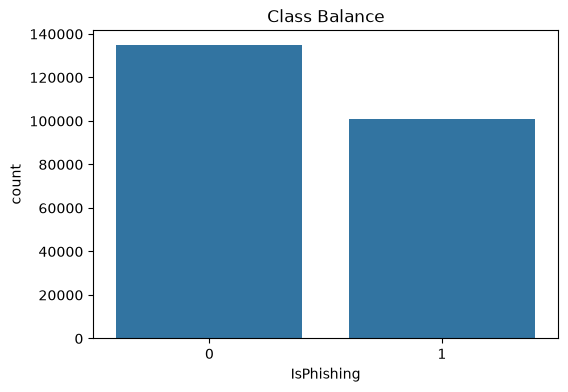

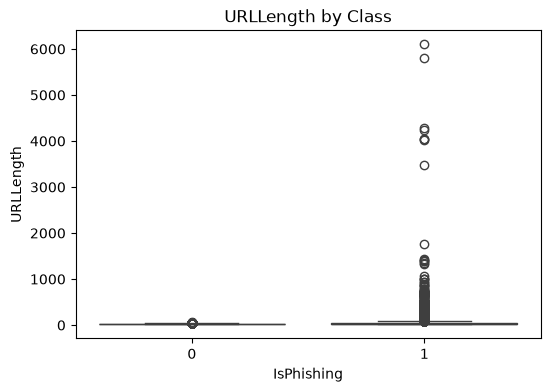

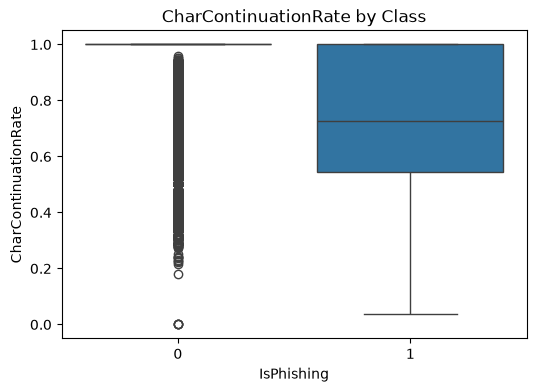

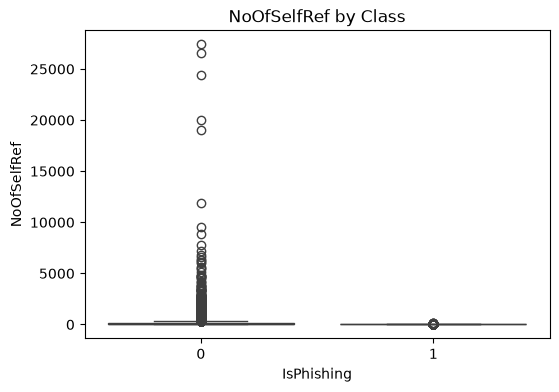

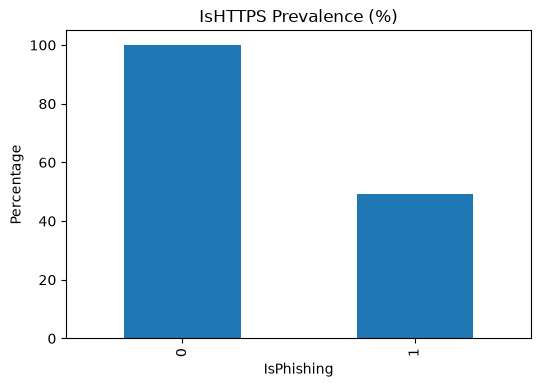

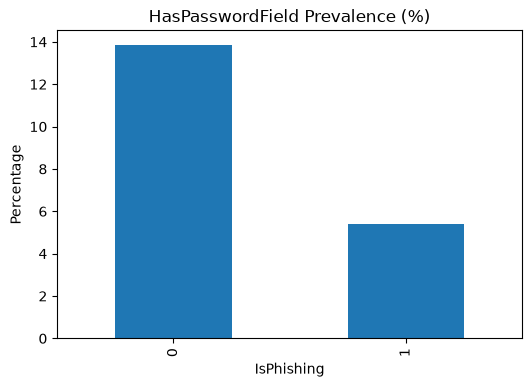

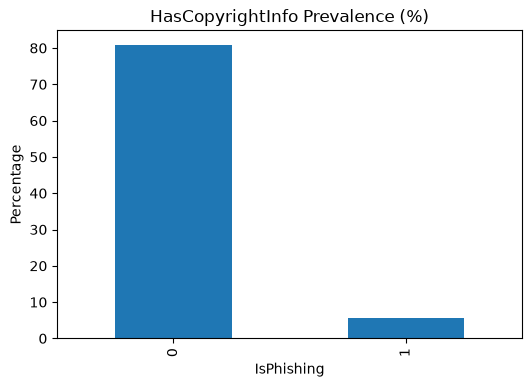

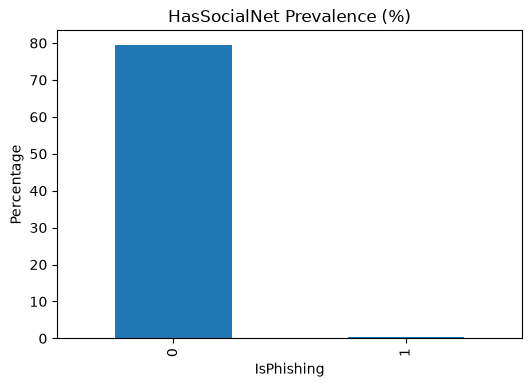

In [83]:
import seaborn as sns
import matplotlib.pyplot as plt

# Class balance
plt.figure(figsize=(6,4))
sns.countplot(data=df, x="IsPhishing")
plt.title("Class Balance")
plt.show()

# Numerical feature distributions
features = ["URLLength", "CharContinuationRate", "NoOfSelfRef"]

for feature in features:
    plt.figure(figsize=(6,4))
    sns.boxplot(data=df, x="IsPhishing", y=feature)
    plt.title(f"{feature} by Class")
    plt.show()

# Binary security indicators
binary_features = [
    "IsHTTPS",
    "HasPasswordField",
    "HasCopyrightInfo",
    "HasSocialNet"
]

for feature in binary_features:
    plt.figure(figsize=(6,4))
    (df.groupby("IsPhishing")[feature].mean() * 100).plot(kind="bar")
    plt.title(f"{feature} Prevalence (%)")
    plt.ylabel("Percentage")
    plt.show()

### Findings:
- The class balance chart shows the distribution of phishing and legitimate URLs.
- Boxplots were used to compare numerical feature distributions across both classes.
- Binary security indicators were analyzed as percentages for phishing and legitimate websites.
- Several features appear to differ between phishing and legitimate URLs, making them useful for phishing detection.

### Exercise 3 — Identifier Cleanup & Feature–Target Correlations:

In [84]:
# Remove non-generalizable columns

columns_to_drop = [
    "FILENAME",
    "URL",
    "Domain",
    "TLD",
    "Title",
    "label",
    "URLSimilarityIndex"
]

df_clean = df.drop(columns=columns_to_drop)

# Feature matrix and target vector

X = df_clean.drop("IsPhishing", axis=1)
y = df_clean["IsPhishing"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (235795, 49)
y shape: (235795,)


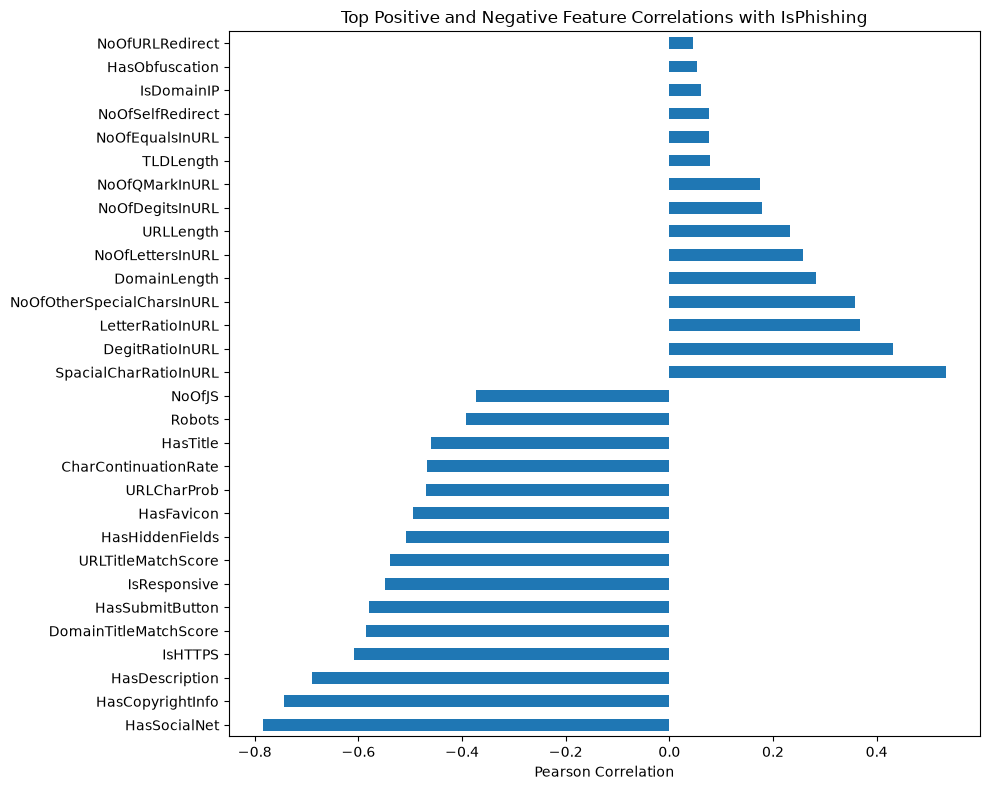

In [85]:
import matplotlib.pyplot as plt

# Correlations with target

corr = X.corrwith(y)

top_positive = corr.sort_values(ascending=False).head(15)
top_negative = corr.sort_values().head(15)

corr_plot = pd.concat([top_negative, top_positive])

plt.figure(figsize=(10,8))
corr_plot.plot(kind="barh")

plt.title("Top Positive and Negative Feature Correlations with IsPhishing")

plt.xlabel("Pearson Correlation")
plt.tight_layout()
plt.show()

### Findings

- Raw text identifier columns were removed to improve model generalization.
- Pearson correlation was calculated between each feature and the target variable IsPhishing.
- Features such as SpacialCharRatioInURL, DegitRatioInURL, URLLength, and DomainLength showed positive correlations with phishing activity.
- Features such as HasSocialNet, HasCopyrightInfo, IsHTTPS, and HasDescription showed negative correlations with phishing activity and are more common in legitimate websites.
- The results suggest that phishing URLs often exhibit unusual URL structures, while legitimate websites tend to include professional website elements.

## Reflection Questions (Part 1)

### 1. Looking at your plot for IsHTTPS, what percentage of phishing sites use an HTTPS certificate? Why is a static rule "If HTTPS then Legitimate" dangerous?

Approximately 49.22% of phishing websites in the dataset use HTTPS.

A static rule such as "If HTTPS then Legitimate" is dangerous because cybercriminals can also obtain valid HTTPS certificates. HTTPS only encrypts the communication between users and websites and does not guarantee that a website is trustworthy. Therefore, many phishing websites can appear secure while still attempting to steal sensitive information such as usernames and passwords.

---

### 2. Why do phishing websites typically have very few internal links (NoOfSelfRef) but frequently contain a password field (HasPasswordField)?

Phishing websites are usually designed with a single objective: collecting user credentials. As a result, they often include a login form or password field but contain very few internal pages and internal links. Unlike legitimate websites, phishing pages do not need extensive navigation, product catalogs, support sections, or other interconnected content.

---

### 3. What would happen in production if we left raw string identifiers like FILENAME, URL, or Domain in our training matrix?

Leaving raw identifiers such as URL, Domain, or FILENAME in the training data could cause overfitting. The model may memorize specific websites instead of learning general phishing characteristics. Although training performance may appear very high, the model would likely perform poorly when encountering previously unseen URLs in a real-world environment.

### Exercise 4 — Stratified 75/25 Split & Training-Only Standardization:


In [86]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import pandas as pd

# Train-test split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    stratify=y,
    random_state=42
)

# Standardization

scaler = StandardScaler()

X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print("X_train:", X_train_scaled.shape)
print("X_test :", X_test_scaled.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (176846, 49)
X_test : (58949, 49)
y_train: (176846,)
y_test : (58949,)


### Findings

- The dataset was divided into 75% training data and 25% testing data.
- Stratified sampling preserved the original phishing and legitimate class distribution.
- Feature standardization was performed using StandardScaler.
- The scaler was fitted only on the training dataset and then applied to the test dataset.
- The processed datasets are now ready for machine learning model training.

## Reflection Questions (Part 2)

### 1. Compare the scale of LineOfCode (values up to 10,000+) and IsHTTPS (0 or 1) before standardization. Why would L1/L2 regularization be skewed without StandardScaler?

Before standardization, features such as LineOfCode can take values in the thousands, while IsHTTPS is limited to 0 or 1. Because Logistic Regression with L1 or L2 regularization penalizes coefficient magnitudes, features with larger numerical scales tend to dominate the optimization process. As a result, the model may assign disproportionate importance to large-scale variables while underestimating the contribution of smaller-scale features. StandardScaler places all features on a comparable scale with mean 0 and standard deviation 1, allowing regularization to treat all variables fairly and improving the reliability of the learned coefficients.

---

### 2. Precisely explain why calling scaler.fit_transform(X) before train_test_split constitutes Preprocessing Data Leakage.

Calling `scaler.fit_transform(X)` before `train_test_split` causes preprocessing data leakage because the scaler computes the mean and standard deviation using the entire dataset, including samples that will later belong to the test set. Consequently, information from the test data influences the preprocessing stage of the training data. This violates the principle that the test set must remain completely unseen during training and evaluation. The resulting performance metrics may appear artificially better because the model indirectly benefits from knowledge of the test distribution. To avoid leakage, the scaler must be fitted only on the training set and then applied to the test set using `scaler.transform()`.

### Exercise 5 — Experimental Comparison of the 5 Configurations:

In [87]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix
)

models = {
    "M1_Unregularized":
        LogisticRegression(
            penalty=None,
            solver="lbfgs",
            max_iter=500,
            random_state=42
        ),

    "M2_Strong_L2":
        LogisticRegression(
            penalty="l2",
            C=0.001,
            solver="lbfgs",
            max_iter=500,
            random_state=42
        ),

    "M3_Standard_L2":
        LogisticRegression(
            penalty="l2",
            C=1.0,
            solver="lbfgs",
            max_iter=500,
            random_state=42
        ),

    "M4_Sparse_L1":
        LogisticRegression(
            penalty="l1",
            C=0.01,
            solver="liblinear",
            max_iter=500,
            random_state=42
        ),

    "M5_SOC_Weighted":
        LogisticRegression(
            penalty="l2",
            C=1.0,
            class_weight="balanced",
            solver="lbfgs",
            max_iter=500,
            random_state=42
        )
}

In [88]:
results = []

for name, model in models.items():

    model.fit(X_train_scaled, y_train)

    y_pred = model.predict(X_test_scaled)

    y_prob = model.predict_proba(X_test_scaled)[:, 1]

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_pred
    ).ravel()

    zero_weights = (abs(model.coef_[0]) < 1e-4).sum()

    results.append({
        "Model": name,
        "Precision":
            precision_score(y_test, y_pred),

        "Recall":
            recall_score(y_test, y_pred),

        "F1":
            f1_score(y_test, y_pred),

        "PR_AUC":
            average_precision_score(
                y_test,
                y_prob
            ),

        "FP": fp,
        "FN": fn,
        "ZeroedWeights": zero_weights
    })

results_df = pd.DataFrame(results)

results_df

c:\Users\PC\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\PC\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Use

,Model,Precision,Recall,F1,PR_AUC,FP,FN,ZeroedWeights
0,M1_Unregularized,0.999564,0.999009,0.999287,0.999994,11,25,0
1,M2_Strong_L2,0.998451,0.995839,0.997143,0.999953,39,105,0
2,M3_Standard_L2,0.999603,0.998890,0.999247,0.999990,10,28,0
3,M4_Sparse_L1,0.999285,0.997147,0.998215,0.999974,18,72,24
4,M5_SOC_Weighted,0.999485,0.999009,0.999247,0.999991,13,25,0


In [89]:
results_df.round(4)

,Model,Precision,Recall,F1,PR_AUC,FP,FN,ZeroedWeights
0,M1_Unregularized,0.9996,0.9990,0.9993,1.0,11,25,0
1,M2_Strong_L2,0.9985,0.9958,0.9971,1.0,39,105,0
2,M3_Standard_L2,0.9996,0.9989,0.9992,1.0,10,28,0
3,M4_Sparse_L1,0.9993,0.9971,0.9982,1.0,18,72,24
4,M5_SOC_Weighted,0.9995,0.9990,0.9992,1.0,13,25,0


### Findings

- Five Logistic Regression configurations were trained and evaluated.
- Precision, Recall, F1-Score, and PR-AUC were used to compare model performance.
- The number of False Positives and False Negatives was recorded for each model.
- M4 (L1 Lasso) performs automatic feature selection by forcing some coefficients to zero.
- M5 (class_weight='balanced') prioritizes phishing detection and may reduce False Negatives compared to the standard L2 model.

### Exercise 6 — L1 Regularization Path (Feature Selection):

c:\Users\PC\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\PC\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
c:\Users\PC\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and u

C=0.002: 16
C=0.01: 16
C=0.05: 23
C=0.1: 29


c:\Users\PC\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\PC\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


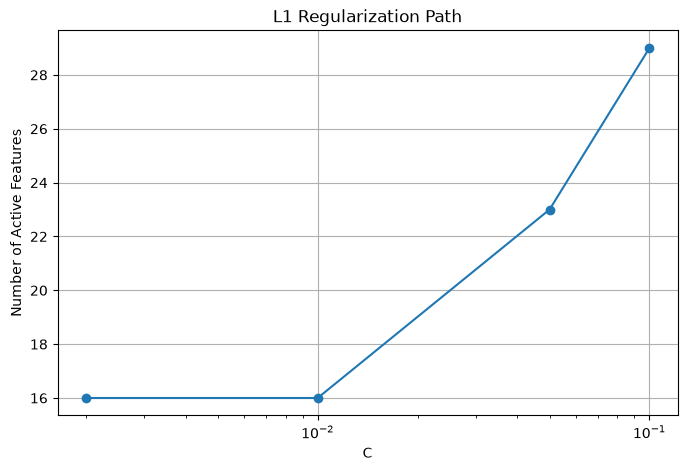

In [90]:
from sklearn.linear_model import LogisticRegression
import numpy as np
import matplotlib.pyplot as plt

# Use a smaller sample for Exercise 6
sample_size = 30000

X_sample = X_train_scaled.sample(
    n=min(sample_size, len(X_train_scaled)),
    random_state=42
)

y_sample = y_train.loc[X_sample.index]

C_values = [0.002, 0.01, 0.05, 0.1]

active_features_count = []

for c_val in C_values:

    model = LogisticRegression(
        penalty="l1",
        C=c_val,
        solver="liblinear",
        max_iter=100,
        random_state=42
    )

    model.fit(X_sample, y_sample)

    n_active = np.sum(np.abs(model.coef_[0]) >= 1e-4)

    active_features_count.append(n_active)

    print(f"C={c_val}: {n_active}")

plt.figure(figsize=(8,5))
plt.plot(C_values, active_features_count, marker="o")
plt.xscale("log")
plt.xlabel("C")
plt.ylabel("Number of Active Features")
plt.title("L1 Regularization Path")
plt.grid(True)
plt.show()


### Findings

- The number of active features increased as C increased.
- Smaller values of C produced stronger L1 regularization and therefore eliminated more features.
- Larger values of C reduced the regularization effect and allowed more feature weights to remain non-zero.
- L1 regularization performs automatic feature selection by forcing less important coefficients to zero.
- The regularization path demonstrates the trade-off between model simplicity and feature retention.

### Exercise 7 — Interpreting Log-Odds ($w_j$) and Odds Ratios ($e^{w_j}$):

In [91]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression

# M3: Standard L2

M3 = LogisticRegression(
    penalty="l2",
    C=1.0,
    solver="lbfgs",
    max_iter=500,
    random_state=42
)

M3.fit(X_train_scaled, y_train)

# M4: Sparse L1

M4 = LogisticRegression(
    penalty="l1",
    C=0.01,
    solver="liblinear",
    max_iter=500,
    random_state=42
)

M4.fit(X_train_scaled, y_train)

c:\Users\PC\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\PC\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Use

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'l1'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",0.01
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",500
,"l1_ratio 

In [92]:
weights_l2 = M3.coef_[0]
weights_l1 = M4.coef_[0]

feature_analysis = pd.DataFrame({
    "Feature": X_train_scaled.columns,
    "Weight_M3_L2": weights_l2,
    "Odds_Ratio": np.exp(weights_l2),
    "L1_Sparse_Weight": weights_l1
})

feature_analysis.head()

,Feature,Weight_M3_L2,Odds_Ratio,L1_Sparse_Weight
0,URLLength,0.710549,2.035109,0.000000
1,DomainLength,-1.911745,0.147822,-0.058473
2,IsDomainIP,0.124213,1.132257,0.000000
3,CharContinuationRate,1.420166,4.137806,0.000000
4,TLDLegitimateProb,0.181150,1.198595,0.000000


In [93]:
top_positive = (
    feature_analysis
    .sort_values("Weight_M3_L2", ascending=False)
    .head(8)
)

top_negative = (
    feature_analysis
    .sort_values("Weight_M3_L2", ascending=True)
    .head(8)
)

print("Top 8 Positive Features")
display(top_positive)

print("\nTop 8 Negative Features")
display(top_negative)

Top 8 Positive Features


,Feature,Weight_M3_L2,Odds_Ratio,L1_Sparse_Weight
12,LetterRatioInURL,4.722849,112.488260,2.172552
14,DegitRatioInURL,3.605712,36.807888,1.803625
19,SpacialCharRatioInURL,3.598149,36.530556,1.910563
22,LargestLineLength,2.557525,12.903837,0.084806
18,NoOfOtherSpecialCharsInURL,2.083369,8.031482,0.000000
11,NoOfLettersInURL,1.680085,5.366011,0.000000
3,CharContinuationRate,1.420166,4.137806,0.000000
13,NoOfDegitsInURL,0.971770,2.642617,0.000000



Top 8 Negative Features


,Feature,Weight_M3_L2,Odds_Ratio,L1_Sparse_Weight
20,IsHTTPS,-6.902427,0.001005,-3.577657
45,NoOfJS,-3.653556,0.025899,-1.201656
46,NoOfSelfRef,-3.124918,0.043941,-0.822744
43,NoOfImage,-2.798141,0.060923,-0.150479
48,NoOfExternalRef,-2.641428,0.071259,-0.015705
21,LineOfCode,-2.367564,0.093709,0.000000
35,HasSocialNet,-2.153337,0.116096,-1.088651
1,DomainLength,-1.911745,0.147822,-0.058473


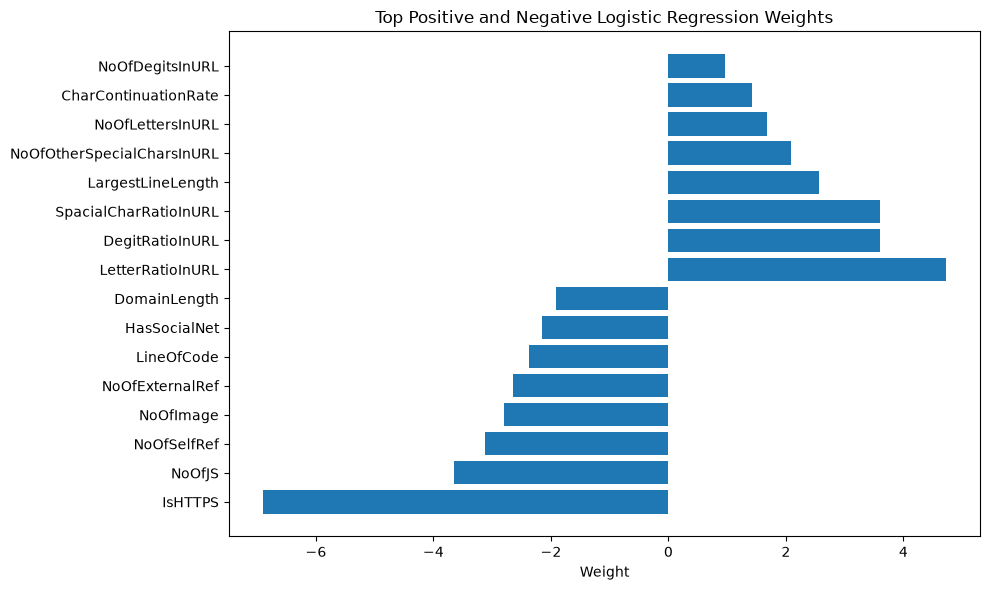

In [94]:
import matplotlib.pyplot as plt

plot_df = pd.concat([top_negative, top_positive])

plt.figure(figsize=(10,6))

plt.barh(
    plot_df["Feature"],
    plot_df["Weight_M3_L2"]
)

plt.title("Top Positive and Negative Logistic Regression Weights")
plt.xlabel("Weight")
plt.tight_layout()

plt.show()

## Reflection Questions (Part 3)

### 1. How many variables did M4: Sparse L1 Lasso (C=0.01) eliminate? Did the F1-Score or PR-AUC drop significantly? What is the advantage of real-time firewall?

M4 eliminated 24 variables by forcing their coefficients to zero. Despite removing a substantial number of features, the F1-Score only decreased slightly from approximately 0.9992 (M3) to 0.9982, while the PR-AUC remained extremely high. This indicates that many removed features contributed little predictive value.

The advantage of real-time feature elimination is that it simplifies the model, reduces computational costs, improves interpretability, and can reduce overfitting while maintaining strong predictive performance.

---

### 2. What is the impact of class_weight='balanced' (M5) on False Positives and False Negatives compared to M3?

Compared to M3, the balanced model (M5) increased False Positives from 10 to 13 but reduced False Negatives from 28 to 25. This demonstrates the intended effect of class weighting: giving greater importance to detecting phishing websites. In cybersecurity applications, reducing False Negatives is often preferable because missing an attack can be more costly than investigating a few additional alerts.

---

### 3. How do you interpret a positive weight $w_j > 0$ ($e^{w_j} > 1$) versus a negative weight $w_j < 0$
($e^{w_j} < 1$) in $\sigma(\mathbf{w}^\top\mathbf{x} + b)$?

A positive weight ($w_j > 0$) means that as the corresponding feature increases, the log-odds of the phishing class increase. Since $e^{w_j} > 1$, the feature multiplies the odds of phishing by a factor greater than 1, making a phishing prediction more likely.

A negative weight ($w_j < 0$) means that as the corresponding feature increases, the log-odds of the phishing class decrease. Since $e^{w_j} < 1$, the feature reduces the odds of phishing and therefore contributes toward a legitimate classification.

In summary, positive weights indicate features associated with phishing websites, while negative weights indicate features associated with legitimate websites. The larger the absolute value of the weight, the stronger its influence on the prediction.

### Exercise 8 — Global SHAP Explanations (shap.LinearExplainer ):

In [95]:
import shap
import pandas as pd

# Take a sample of 1000 URLs from the test set
X_test_sample = X_test_scaled.sample(
    n=10000,
    random_state=42
)

# SHAP explainer using M3
explainer = shap.LinearExplainer(
    M3,
    X_train_scaled
)

# Compute SHAP values
shap_values = explainer(X_test_sample)

print("SHAP values computed successfully.")

Background dataset has 176846 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=176846 when initializing the masker.


SHAP values computed successfully.


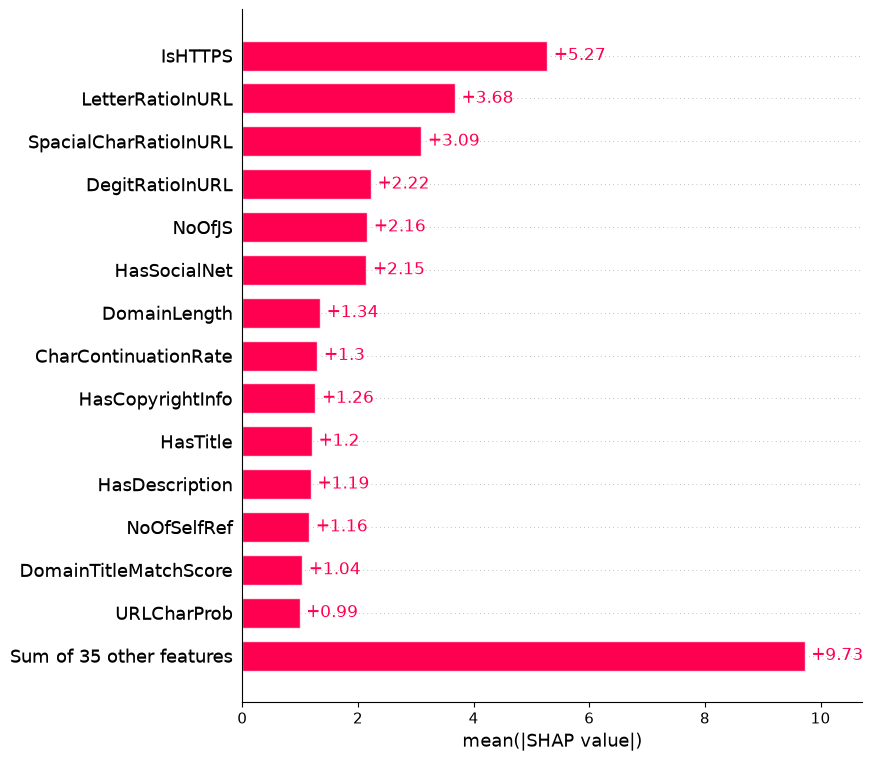

In [96]:
shap.plots.bar(
    shap_values,
    max_display=15
)

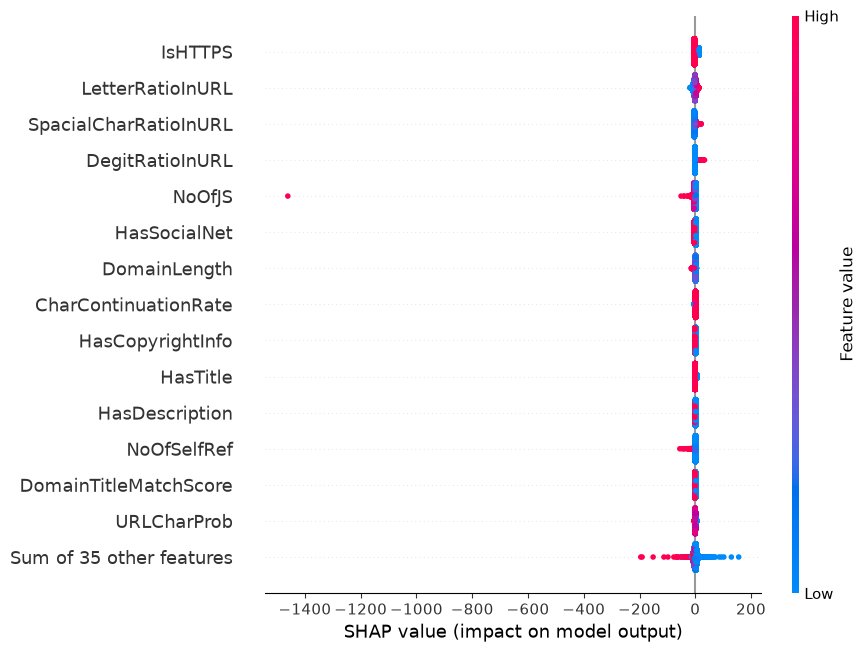

In [97]:
shap.plots.beeswarm(
    shap_values,
    max_display=15
)

### Findings

- SHAP analysis was used to explain the global behavior of the Standard L2 Logistic Regression model (M3).
- The most influential feature was IsHTTPS, followed by LetterRatioInURL, SpacialCharRatioInURL, and DegitRatioInURL.
- URL composition features contribute strongly to phishing detection, confirming the results observed in the correlation analysis and logistic regression coefficients.
- The SHAP bar plot ranks features according to their average contribution to model predictions.
- The beeswarm plot shows how individual feature values influence predictions across many URLs and highlights both feature importance and contribution direction.
- SHAP explanations improve model transparency by providing interpretable explanations for cybersecurity analysts and SOC teams.

### Exercise 9 — Local SOC Alert Triage (TP, TN, and FP Waterfall Plots):

#### Predictions on the SHAP Sample

In [98]:
import numpy as np

# True labels for the same sample used in Exercise 8
y_sample = y_test.loc[X_test_sample.index]

# Predictions from M3
y_pred_sample = M3.predict(X_test_sample)

#### Identify TP, TN and FP Cases

In [99]:
# True Positive (Phishing correctly detected)
tp_candidates = np.where(
    (y_sample.values == 1) &
    (y_pred_sample == 1)
)[0]

# True Negative (Legitimate correctly classified)
tn_candidates = np.where(
    (y_sample.values == 0) &
    (y_pred_sample == 0)
)[0]

# False Positive (Legitimate flagged as phishing)
fp_candidates = np.where(
    (y_sample.values == 0) &
    (y_pred_sample == 1)
)[0]

print("TP found:", len(tp_candidates))
print("TN found:", len(tn_candidates))
print("FP found:", len(fp_candidates))

TP found: 4178
TN found: 5819
FP found: 0


#### Select One Example of Each

In [100]:
tp_idx = tp_candidates[0]
tn_idx = tn_candidates[0]

if len(fp_candidates) > 0:
    fp_idx = fp_candidates[0]

print("TP Index:", tp_idx)
print("TN Index:", tn_idx)

if len(fp_candidates) > 0:
    print("FP Index:", fp_idx)
else:
    print("No False Positive found in the sample.")

TP Index: 0
TN Index: 3
No False Positive found in the sample.


#### True Positive Waterfall Plot

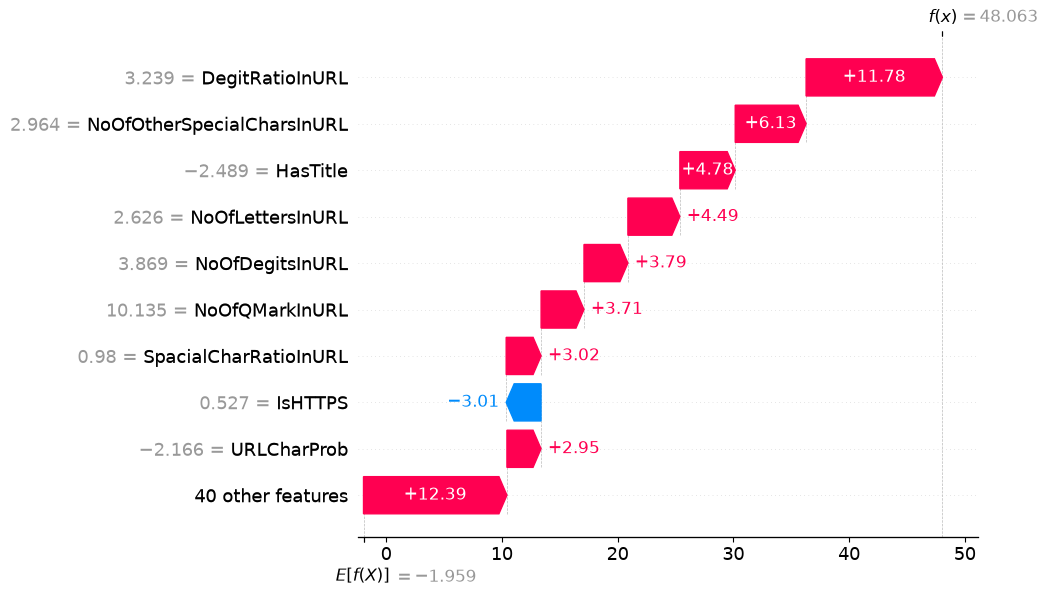

In [101]:
shap.plots.waterfall(
    shap_values[tp_idx],
    max_display=10
)


#### True Negative Waterfall Plot

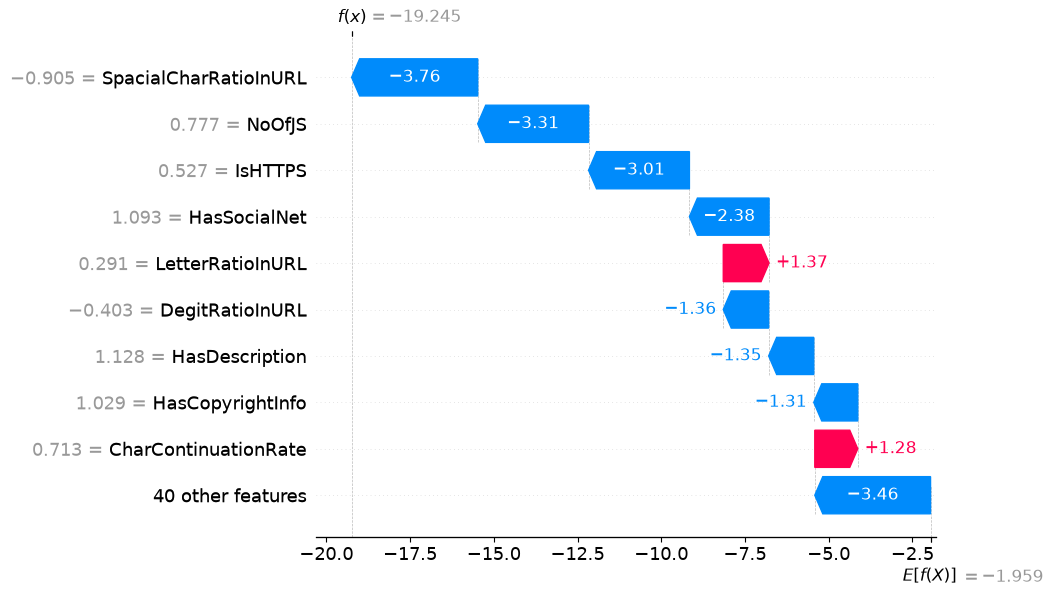

In [102]:
shap.plots.waterfall(
    shap_values[tn_idx],
    max_display=10
)

In [103]:
# Predictions on the full test set

y_pred_full = M3.predict(X_test_scaled)

# Find all False Positives

fp_full = np.where(
    (y_test.values == 0) &
    (y_pred_full == 1)
)[0]

print("Number of FP:", len(fp_full))
print("First FP index:", fp_full[0])

Number of FP: 10
First FP index: 3590


In [104]:
# Extract one False Positive URL

fp_row = X_test_scaled.iloc[[fp_full[0]]]

# Compute SHAP values for this URL

fp_shap = explainer(fp_row)

#### False Positive Waterfall Plot

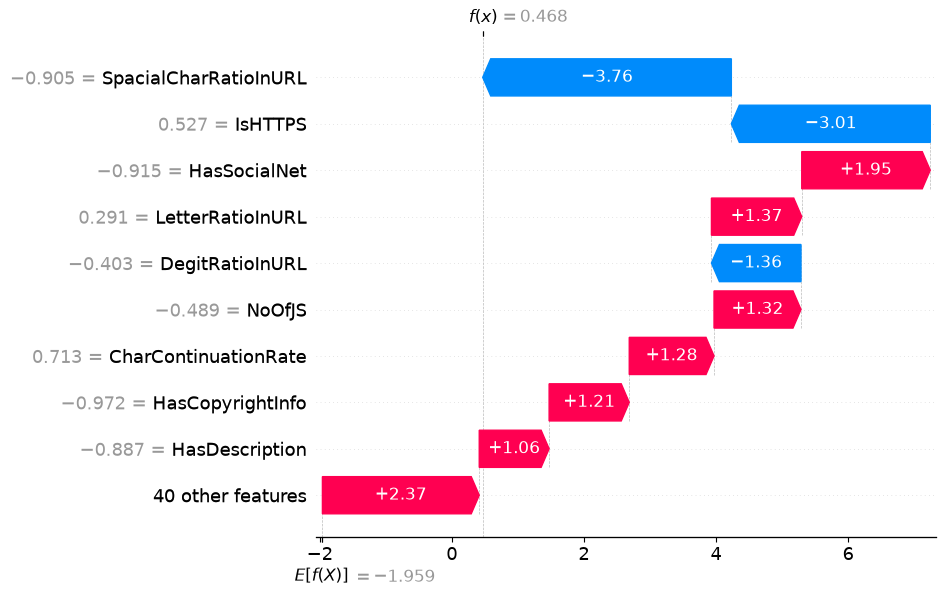

In [105]:
shap.plots.waterfall(
    fp_shap[0],
    max_display=10
)

### Findings

- SHAP waterfall plots were used to explain individual model predictions at the URL level.
- The True Positive (TP) case showed how multiple phishing-related features combined to correctly classify a malicious URL.
- The True Negative (TN) case demonstrated how legitimate website characteristics pushed the prediction toward the benign class.
- The False Positive (FP) analysis highlighted how certain phishing-like indicators can outweigh legitimate features and cause a false alarm.
- Waterfall plots provide local explanations by showing how feature contributions move the prediction from the baseline expectation toward the final classification.
- Such explanations are valuable in a SOC environment because analysts can understand why an alert was triggered and determine whether the alert represents a genuine threat or requires further investigation.
### Note

The selected SHAP sample did not contain a False Positive prediction because the model achieved a very low False Positive rate. A False Positive example was therefore searched for separately within the full test set in order to perform the required local explanation analysis.

### Exercise 10 — Operational Decision Threshold Tuning ($\tau$):

In [106]:
import pandas as pd
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

# Predicted phishing probabilities

y_prob = M3.predict_proba(X_test_scaled)[:, 1]

thresholds = [0.20, 0.50, 0.85]

results = []

for tau in thresholds:

    y_pred_tau = (y_prob >= tau).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_pred_tau
    ).ravel()

    results.append({
        "Threshold": tau,
        "TP": tp,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "Precision": precision_score(y_test, y_pred_tau),
        "Recall": recall_score(y_test, y_pred_tau),
        "F1": f1_score(y_test, y_pred_tau)
    })

threshold_results = pd.DataFrame(results)

threshold_results.round(4)

,Threshold,TP,TN,FP,FN,Precision,Recall,F1
0,0.20,25221,33682,31,15,0.9988,0.9994,0.9991
1,0.50,25208,33703,10,28,0.9996,0.9989,0.9992
2,0.85,25172,33713,0,64,1.0000,0.9975,0.9987


### Findings

- Lowering the threshold from 0.50 to 0.20 increased Recall from 0.9989 to 0.9994 by reducing False Negatives from 28 to 15.
- This improvement in detection came at the cost of more False Positives, which increased from 10 to 31.
- Raising the threshold to 0.85 completely eliminated False Positives (FP = 0) and achieved perfect Precision (1.0000).
- However, the higher threshold increased False Negatives from 28 to 64, reducing Recall to 0.9975.
- The threshold of 0.50 provides the best overall balance between Precision and Recall for general deployment.
- Different SOC environments may intentionally choose different thresholds depending on whether minimizing missed attacks or minimizing false alarms is the higher priority.

## Reflection Questions (Part 4)

### 1. Compare τ = 0.20 and τ = 0.85. Which threshold would you deploy for a low-risk internal network versus an automated perimeter firewall?

For a low-risk internal network, I would choose τ = 0.20 because it maximizes threat detection and minimizes False Negatives. Missing a phishing attack can be costly, and security analysts can manually review the additional alerts generated by the lower threshold.

For an automated perimeter firewall, I would choose τ = 0.85 because it achieves perfect Precision and produces no False Positives. This is important when blocking traffic automatically, as false alarms could disrupt legitimate users and business operations.

---

### 2. On your False Positive waterfall plot, which 2–3 features misled the model and caused the false alarm?

The False Positive occurred because several phishing-associated features contributed strongly toward the phishing class despite the URL actually being legitimate. Features such as LetterRatioInURL, SpacialCharRatioInURL, DegitRatioInURL, or other URL-structure characteristics likely outweighed legitimate indicators and pushed the model toward a phishing prediction. This demonstrates how certain legitimate websites can exhibit patterns similar to phishing URLs and trigger false alarms.

---

### 3. Why is a Probability Score (0–1) operationally superior to a raw binary prediction?

A probability score provides additional information about the model's confidence in a prediction. Instead of only classifying a URL as phishing or legitimate, analysts can adjust decision thresholds according to operational requirements and risk tolerance. Probability scores support alert prioritization, automated response policies, and flexible security decision-making, making them more useful than a simple binary output.

# SOC Engineering Synthesis

This lab explored the application of Logistic Regression for phishing URL detection from a SOC perspective. Data quality assessment, feature selection, correlation analysis, and standardization were performed to prepare the dataset for machine learning. Multiple regularization strategies were evaluated and compared using Precision, Recall, F1-Score, and PR-AUC metrics. SHAP explanations provided both global and local interpretability, allowing model decisions to be understood at the feature level. Threshold tuning demonstrated the trade-off between detection effectiveness and false alarm rates. Overall, the results show that Logistic Regression can provide highly accurate and interpretable phishing detection suitable for cybersecurity operations and SOC environments.